## This notebook is for plotting the count of objects as well as the area of object for series A



In [1]:
import pandas as pd
#barcode_plate = pd.read_csv('Barcode_plates_new.txt',delimiter=r' ', engine="python", header=None, error_bad_lines=False)
#barcode_plate


with open("Barcode_plates_new.txt", "r") as f:
    lines = [line.strip().split() for line in f]

# Convert to DataFrame with flexible column count
barcode_plate = pd.DataFrame(lines,columns=['Barcode','Plate','4fields'])

# Fill missing values with a specific value
barcode_plate = barcode_plate.fillna("")  

barcode_plate


,Barcode,Plate,4fields
0,Barcode,Plate,4fields
1,20170516-SA-12022-01A,MFGTMPcx7_170525010001,
2,20170516-SA-12022-01B,MFGTMPcx7_170524170002,
3,20170516-SA-12022-01C,MFGTMPcx7_170525050001,
4,20170516-SA-12022-01D,MFGTMPcx7_170524210001,
...,...,...,...
228,20170725-SA-12041-78D,MFGTMPcx7_170801190001,
229,20170725-SA-12053-79A,MFGTMPcx7_170802000001,
230,20170725-SA-12053-79B,MFGTMPcx7_170802050001,
231,20170725-SA-12053-79C,MFGTMPcx7_170802100001,


Run the next cell for xticks in plots (barcode number + group number)

In [3]:
Barcode= [ba+str((bool(f))).replace('True','*').replace('False','') for ba,f in zip(barcode_plate['Barcode'],barcode_plate['4fields'])]
Barcode


['Barcode*',
 '20170516-SA-12022-01A',
 '20170516-SA-12022-01B',
 '20170516-SA-12022-01C',
 '20170516-SA-12022-01D',
 '20170516-SA-12023-02A*',
 '20170516-SA-12023-02B*',
 '20170516-SA-12023-02C*',
 '20170516-SA-12023-02D*',
 '20170516-SA-12024-03A*',
 '20170516-SA-12024-03B*',
 '20170516-SA-12024-03C*',
 '20170516-SA-12024-03D*',
 '20170516-SA-12025-04A*',
 '20170516-SA-12025-04B*',
 '20170516-SA-12025-04C*',
 '20170516-SA-12025-04D*',
 '20170522-SA-12026-05A',
 '20170522-SA-12026-05B',
 '20170522-SA-12026-05C',
 '20170522-SA-12026-05D',
 '20170522-SA-12027-06A',
 '20170522-SA-12027-06B',
 '20170522-SA-12027-06C',
 '20170522-SA-12027-06D',
 '20170522-SA-12028-07A',
 '20170522-SA-12028-07B',
 '20170522-SA-12028-07C',
 '20170522-SA-12028-07D',
 '20170522-SA-12029-08A',
 '20170522-SA-12029-08B',
 '20170522-SA-12029-08C',
 '20170522-SA-12029-08D',
 '20170523-SA-12030-09A',
 '20170523-SA-12030-09B',
 '20170523-SA-12030-09C',
 '20170523-SA-12030-09D',
 '20170523-SA-12031-10A',
 '20170523-SA

In [4]:
## These libraries should be imported
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np 

Text(0.5, 1.0, 'samples')

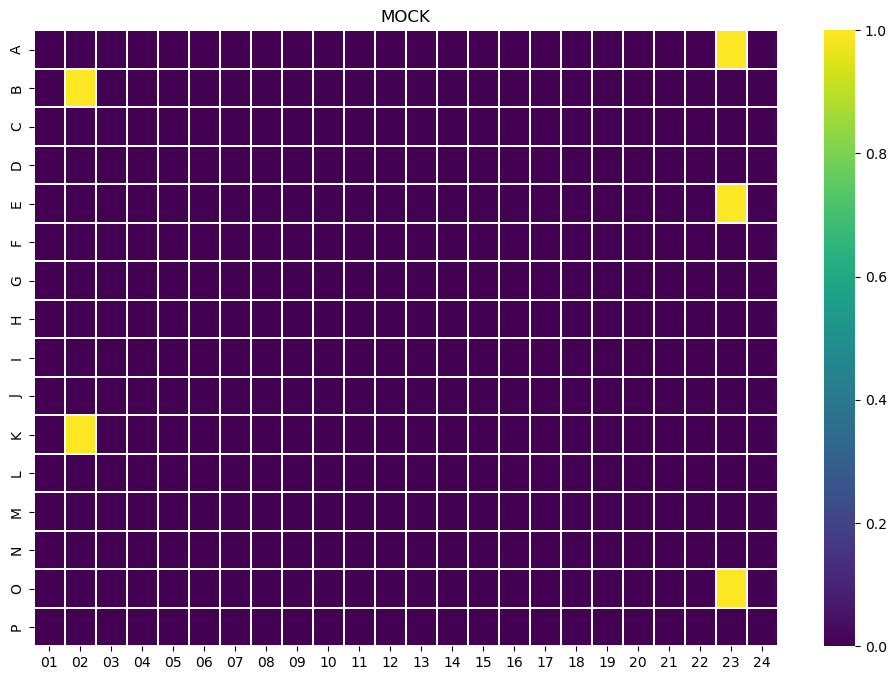

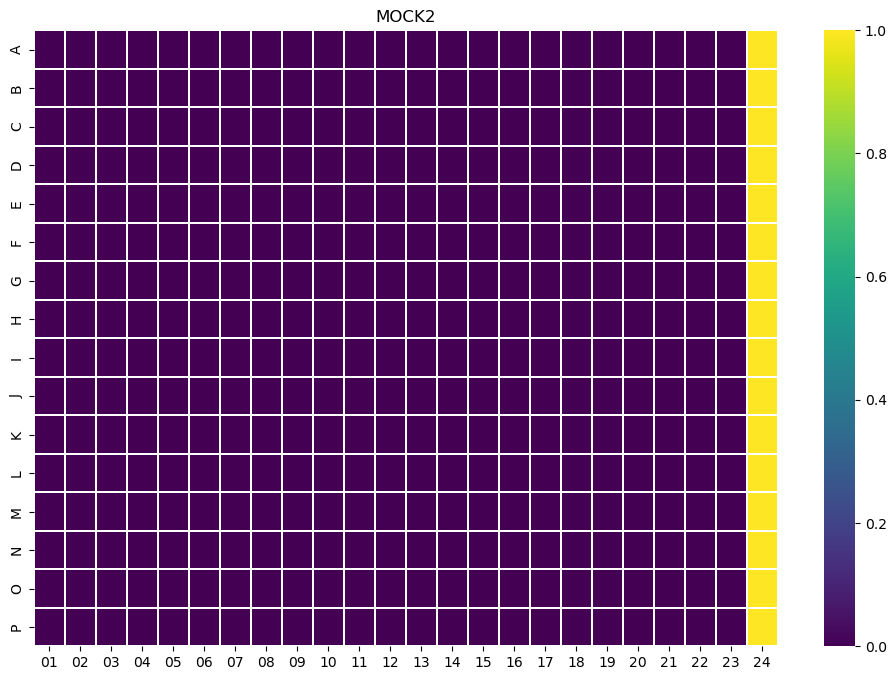

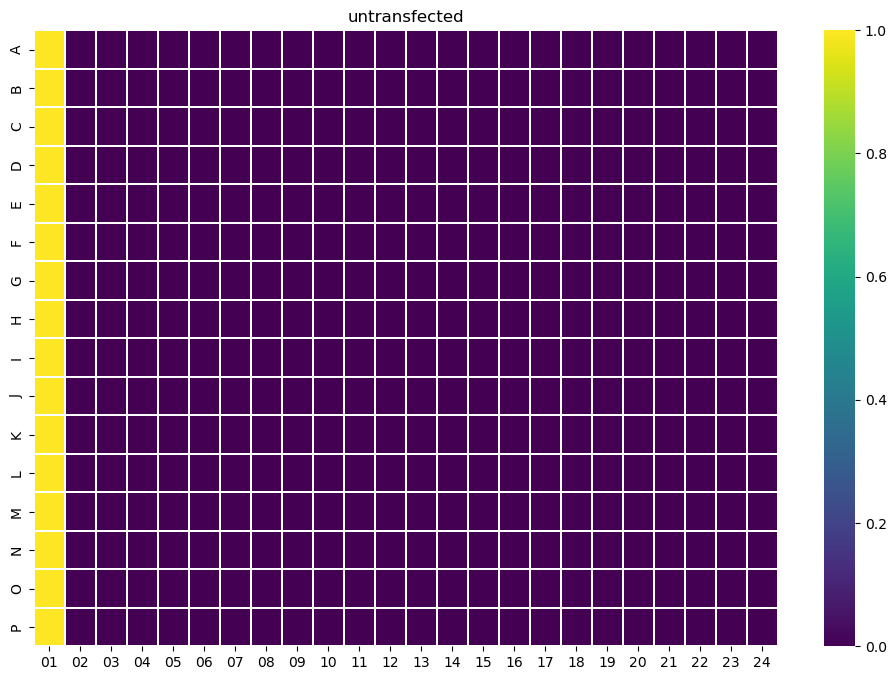

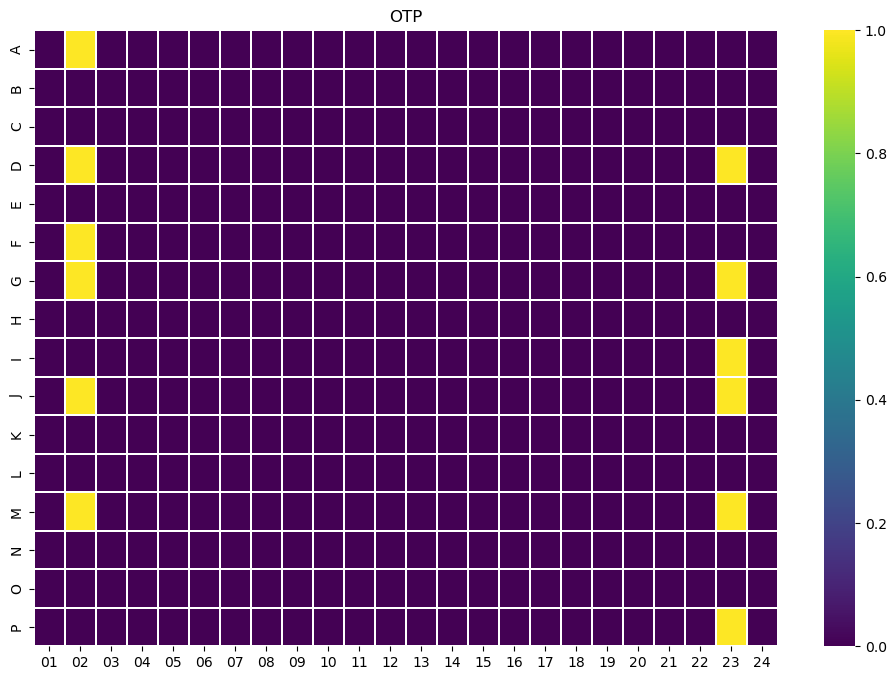

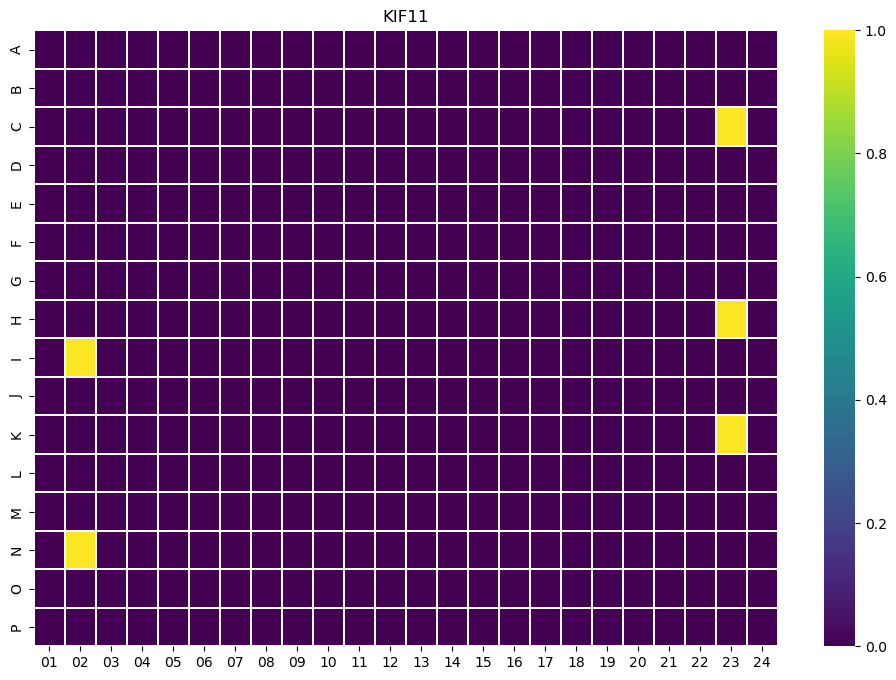

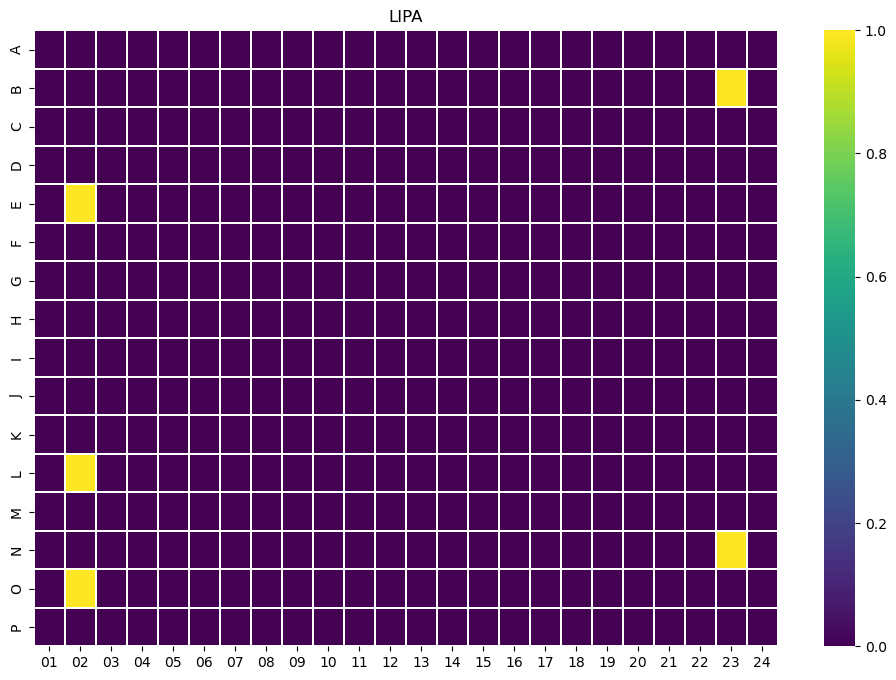

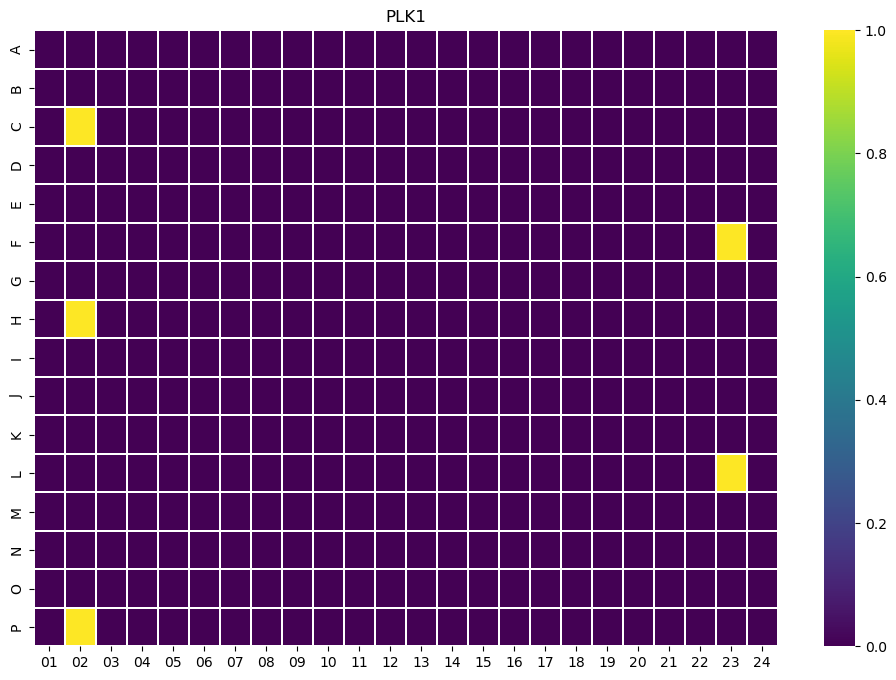

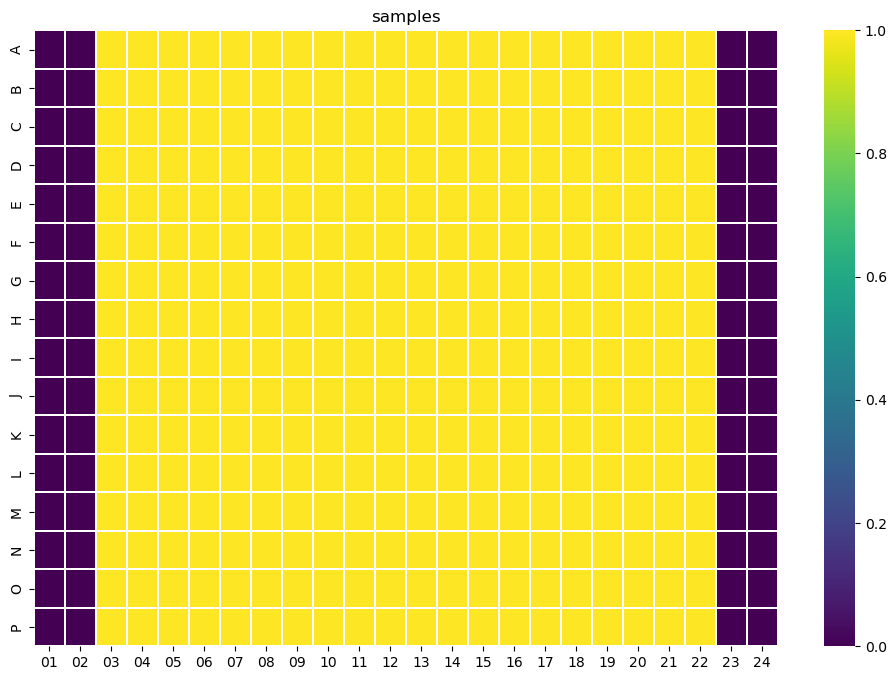

In [5]:
## This cell is important for defining control and sample columns
##necessary for plots

import numpy as np
import pandas as pd
row_number = ['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P']
column_number = ['01','02','03','04','05','06','07','08','09','10','11','12','13','14','15','16','17','18','19','20','21','22','23','24']



### Mock ##########################################
zero_data = np.zeros(shape=(16,24))
mock = pd.DataFrame(zero_data,columns=column_number,index=row_number,dtype=int)
#mock_list_r = !cat control.txt | grep mock | cut -f 1 | cut -b 1
mock_list_r = []
mock_list_c = []

with open("control.txt", "r") as file:
    for line in file:
        if "mock" in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                mock_list_r.append(first_field[1:4])
                mock_list_c.append(first_field[0])

for c,r in zip(mock_list_c,mock_list_r):
    mock.loc[c, r] = 1

plt.figure(figsize=(12,8))
sns.heatmap(np.array(mock),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('MOCK')



### Mock 2 ###################################
zero_data = np.zeros(shape=(16,24))
mock2 = pd.DataFrame(zero_data,columns=column_number,index=row_number,dtype=int)

mock2_list_r = []
mock2_list_c = []

with open("control.txt", "r") as file:
    for line in file:
        if "Mock2" in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                mock2_list_r.append(first_field[1:4])
                mock2_list_c.append(first_field[0])


for c,r in zip(mock2_list_c,mock2_list_r):
    mock2.loc[c,r] = 1
plt.figure(figsize=(12,8))
sns.heatmap(np.array(mock2),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('MOCK2')
##################################################

#### unstransfected wells ########################
untr_list_r = []
untr_list_c = []
zero_data = np.zeros(shape=(16,24))
untr = pd.DataFrame(zero_data,columns=column_number,index=row_number,dtype=int)
with open ("control.txt","r") as file:
    for line in file:
        if 'untransfected' in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                untr_list_c.append(first_field[0])
                untr_list_r.append(first_field[1:4])

for c,r in zip(untr_list_c,untr_list_r):
    untr.loc[c,r] = 1
plt.figure(figsize=(12,8))
sns.heatmap(np.array(untr),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('untransfected')

###################################################
###############OTP ###############################

zero_data = np.zeros(shape=(16,24))
OTP = pd.DataFrame(zero_data,columns=column_number,index=row_number)
OTP_list_r = []
OTP_list_c = []

with open ("control.txt","r") as file:
    for line in file:
        if 'OTP' in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                OTP_list_c.append(first_field[0])
                OTP_list_r.append(first_field[1:4])


for c,r in zip(OTP_list_c,OTP_list_r):
    OTP.loc[c,r] = 1
plt.figure(figsize=(12,8))
sns.heatmap(np.array(OTP),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('OTP')



#################### KIF11 ######################
KIF11_list_c = []
KIF11_list_r = []

zero_data = np.zeros(shape=(16,24))
KIF11 = pd.DataFrame(zero_data,columns=column_number,index=row_number)
with open ("control.txt","r") as file:
    for line in file:
        if 'KIF11' in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                KIF11_list_c.append(first_field[0])
                KIF11_list_r.append(first_field[1:4])



for c,r in zip(KIF11_list_c,KIF11_list_r):
    KIF11.loc[c,r] = 1
plt.figure(figsize=(12,8))
sns.heatmap(np.array(KIF11),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('KIF11')
  
###############################################
# #######################LIPA #################  
LIPA_list_r = []
LIPA_list_c = []
zero_data = np.zeros(shape=(16,24))
LIPA=pd.DataFrame(zero_data,columns=column_number,index=row_number)
with open ("control.txt","r") as file:
    for line in file:
        if 'LIPA' in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                LIPA_list_c.append(first_field[0])
                LIPA_list_r.append(first_field[1:4])   

for c,r in zip(LIPA_list_c,LIPA_list_r):
    LIPA.loc[c,r] = 1
plt.figure(figsize=(12,8))
sns.heatmap(np.array(LIPA),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('LIPA')
###############################################
####################### PLK1 ##################
PLK1_list_c=[]
PLK1_list_r=[]
zero_data = np.zeros(shape=(16,24))
PLK1=pd.DataFrame(zero_data,columns=column_number,index=row_number)
with open ("control.txt","r") as file:
    for line in file:
        if 'PLK1' in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                PLK1_list_c.append(first_field[0])
                PLK1_list_r.append(first_field[1:4])
for c,r in zip(PLK1_list_c,PLK1_list_r):
    PLK1.loc[c,r] = 1
plt.figure(figsize=(12,8))
sns.heatmap(np.array(PLK1),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('PLK1')

###############################################

zero_data = np.ones(shape=(16,24))
wells=pd.DataFrame(zero_data,columns=column_number,index=row_number)
samples = wells-mock-mock2-LIPA-KIF11-OTP-untr-PLK1

plt.figure(figsize=(12,8))
sns.heatmap(np.array(samples),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('samples')




The next cell is important for plate Number
Always run before each plot

### Don't run the next cell
It is for creating count or area matrix
run only if you do not have .json files and want to create from .csv file

Other wise DO NOT run

In [55]:
# this is for number of cells
row_number = ['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P']
column_number = ['01','02','03','04','05','06','07','08','09','10','11','12','13','14','15','16','17','18','19','20','21','22','23','24']

#Create empty list
my_dict_cellNr = {}

# Access the value using the key
#my_dict_cellNr["170524210001"] 
for p in plateNr:
    temp_df = pd.read_csv('csv_files/A/4field/MFGTMPcx7_'+p+'.csv')
    new_df_cell_number = pd.DataFrame(columns=column_number,index=row_number)
    for r in row_number:
        for c in column_number:
            well = r+c
            new_df_cell_number.loc[r][c] = len(temp_df[temp_df['Image_name'].str.contains(p+'_'+well)]['Area']) #len function counts cells
    my_dict_cellNr[p]=new_df_cell_number


### Don't run the next cell
It is for saving .json files of _count or _area
run only if you do not have .json files and want to create from .csv file run it after previous cell

In [56]:
# Saves dictionaries in json files, remove names of plates you already have jsons for in cell above before running
import json
for k in my_dict_cellNr.keys():
    json.dump(my_dict_cellNr[k].to_json(orient='split'), open('csv_files/A/4field/'+k+'_count.json', 'w'))
    

### Run the following cell if you are going to plot _count plots (raw and normalized)

In [7]:
Barcode_A    = [ba for ba in barcode_plate['Barcode'] if ba.endswith('A')]
print(len(Barcode_A))
Barcode_A  


58


['20170516-SA-12022-01A',
 '20170516-SA-12023-02A',
 '20170516-SA-12024-03A',
 '20170516-SA-12025-04A',
 '20170522-SA-12026-05A',
 '20170522-SA-12027-06A',
 '20170522-SA-12028-07A',
 '20170522-SA-12029-08A',
 '20170523-SA-12030-09A',
 '20170523-SA-12031-10A',
 '20170523-SA-12032-11A',
 '20170529-SA-12034-13A',
 '20170529-SA-12035-14A',
 '20170529-SA-12036-15A',
 '20170530-SA-12038-17A',
 '20170530-SA-12039-18A',
 '20170530-SA-12040-19A',
 '20170613-SA-12050-29A',
 '20170613-SA-12051-30A',
 '20170613-SA-12052-31A',
 '20170614-SA-12054-33A',
 '20170614-SA-12055-34A',
 '20170614-SA-12056-35A',
 '20170614-SA-12057-36A',
 '20170619-SA-12058-37A',
 '20170619-SA-12001-38A',
 '20170619-SA-12002-39A',
 '20170626-SA-12008-45A',
 '20170626-SA-12009-46A',
 '20170626-SA-12010-47A',
 '20170626-SA-12011-48A',
 '20170627-SA-12012-49A',
 '20170703-SA-12016-53A',
 '20170703-SA-12017-54A',
 '20170703-SA-12018-55A',
 '20170704-SA-12020-57A',
 '20170704-SA-12021-58A',
 '20170704-SA-12042-59A',
 '20170704-S

In [ ]:
# This is for counting number of cells 

C:\Users\salma\AppData\Local\Temp\ipykernel_17412\3859020037.py:59: RuntimeWarning: Mean of empty slice.
  otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
c:\Users\salma\.conda\envs\SalmaEnv\envs\coderefinery\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


58


C:\Users\salma\AppData\Local\Temp\ipykernel_17412\3859020037.py:174: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(label_X, rotation=90)


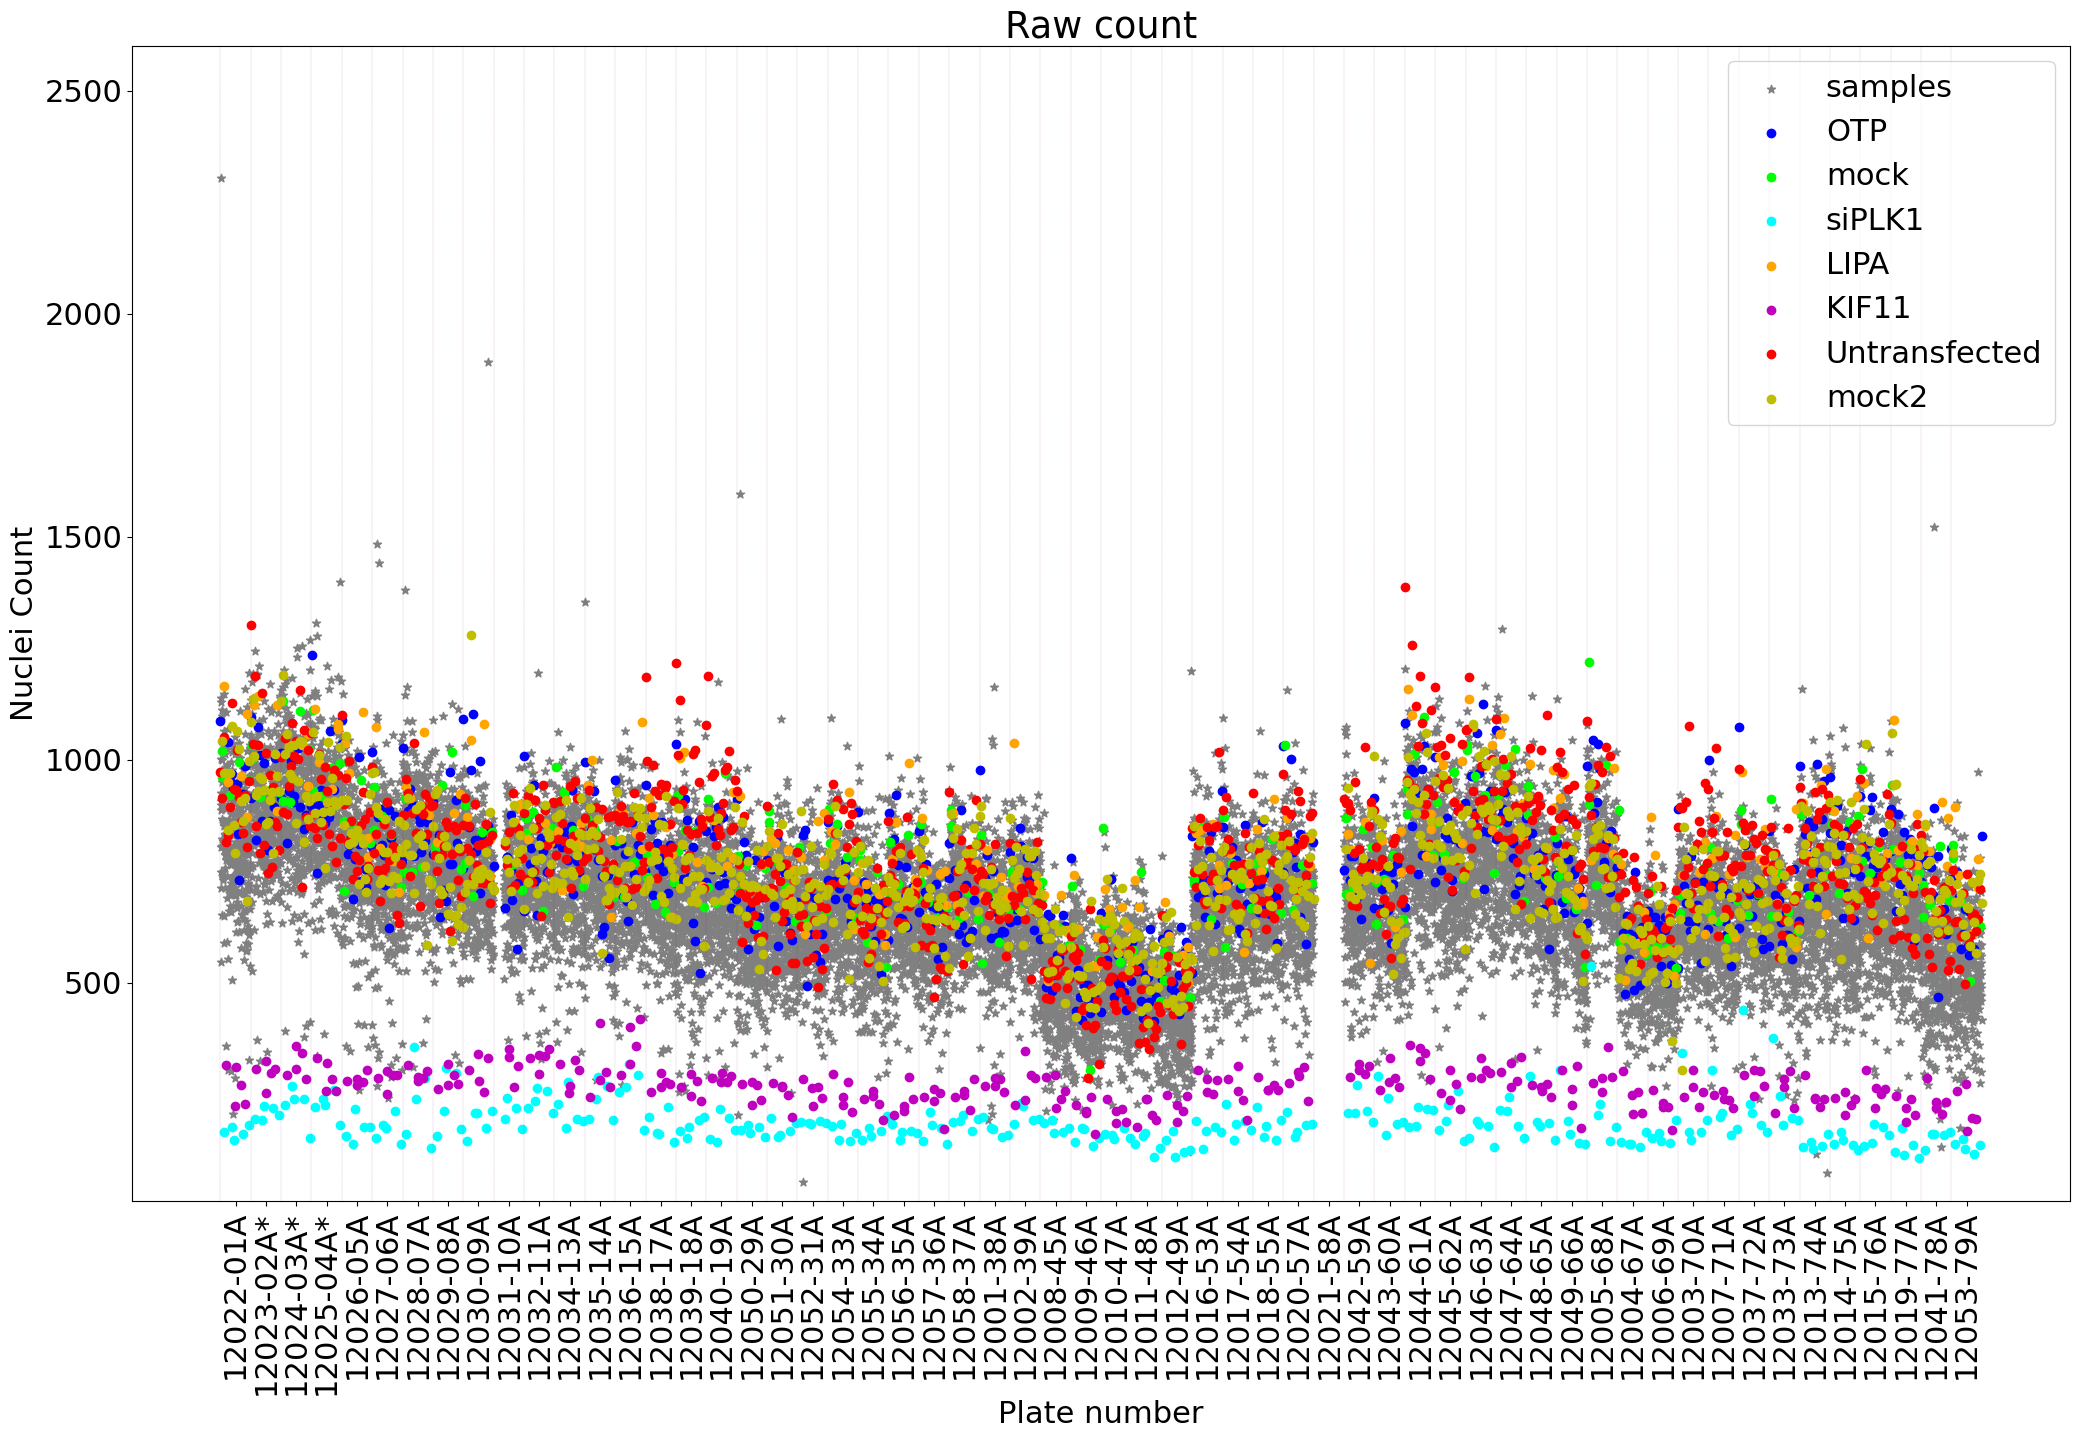

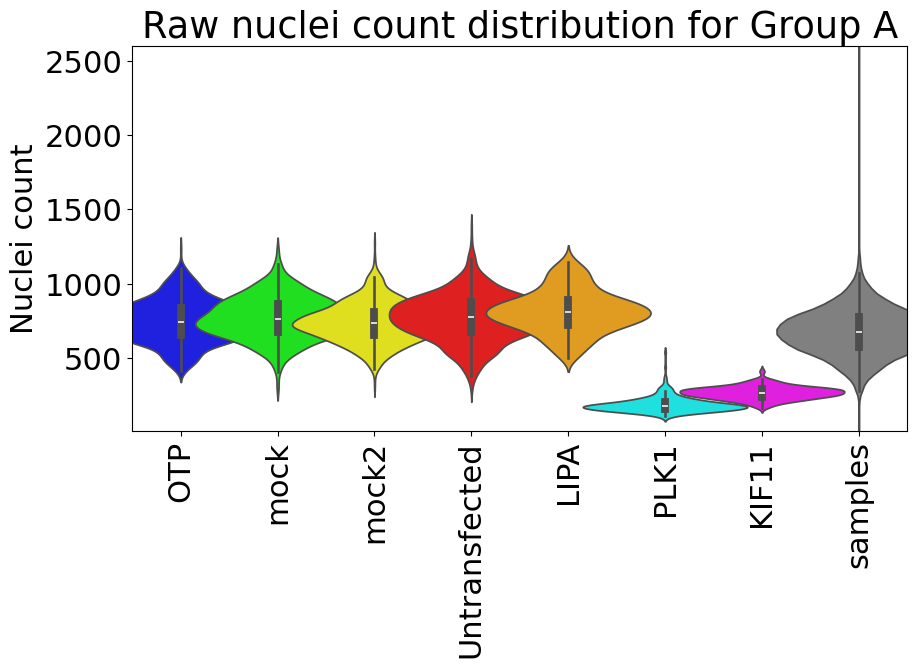

In [9]:
#COPY
# Reads saved json files

#import json so you dont have to run above cell if no new files needs saving
import json
import numpy as np
import os

#make all jsonfiles into keys


#create empty list
l = []
mock_well = []
OTP_well  = []
KIF11_well =[]
LIPA_well = []
PLK1_well = []
mock2_well= []
untr_well = []
label_X = []
all_plate_well = []

#loop through all keys (jsonfiles), load, add key to the empty list l
for k in Barcode_A:
    f4 = barcode_plate.loc[barcode_plate['Barcode']==k,'4fields'].values[0]
    
    lb = k.split('-SA-')[1]+str((bool(f4))).replace('True','*').replace('False','')
    label_X.append(lb)
    plate_data = np.zeros([16,24])
    pl   = barcode_plate.loc[barcode_plate['Barcode']==k, 'Plate'].values[0]

    if len(pl) != 0:
        with open('csv_files/A/'+pl.replace('MFGTMPcx7_','')+'_count.json','r') as f:
        
        ###Normalizing to avg of OTP wells
            json_str   = json.load(f)
            json_dict  = json.loads(json_str)
            plate_data = np.array(json_dict['data'])
             ##OTP


            ## This whole part is for adding 4 more field##
            P_ID  = pl
            
            ff =barcode_plate.loc[barcode_plate['Plate']==P_ID, '4fields'].values[0]
            fourfields = 'csv_files/A/4field/'+ff.replace('MFGTMPcx7_','')+'_count.json'
            if os.path.exists(fourfields):
                with open(fourfields,'r') as f:
                    second_json_4fields = json.load(f)
                    second_json_dict_4fields = json.loads(second_json_4fields)


                    second_plate_data = np.array(second_json_dict_4fields['data'])
                    plate_data = (plate_data+second_plate_data)*0.8


    OTP_per_plate =plate_data *np.array(OTP)
    otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
    plate_data = plate_data


    ##samples
    l.append(plate_data*np.array(samples))

    ##controls
    mock_well.append(plate_data*np.array(mock))
    OTP_well.append(plate_data*np.array(OTP))
    KIF11_well.append(plate_data*np.array(KIF11))
    LIPA_well.append(plate_data*np.array(LIPA))
    PLK1_well.append(plate_data*np.array(PLK1))
    mock2_well.append(plate_data*np.array(mock2))
    untr_well.append(plate_data*np.array(untr))

    all_plate_well.append(plate_data)
      
            

          
    

#label_X= plateNr
print(len(label_X))
       
#make list into array
array_all_plates = np.array(l)
mock_plates = np.array(mock_well)
OTP_plates = np.array(OTP_well)
KIF11_plates = np.array(KIF11_well)
LIPA_plates = np.array(LIPA_well)
PLK1_plates = np.array(PLK1_well)
untr_plates = np.array(untr_well)
mock2_plates = np.array(mock2_well)


all_plates = np.array(all_plate_well)


num_of_plates = len(Barcode_A)


all_for_plot = np.zeros([1,num_of_plates*384])
mock_for_plot = np.zeros([1,num_of_plates*384])
OTP_for_plot = np.zeros([1,num_of_plates*384])
KIF11_for_plot = np.zeros([1,num_of_plates*384])
LIPA_for_plot = np.zeros([1,num_of_plates*384])
PLK1_for_plot = np.zeros([1,num_of_plates*384])
untr_for_plot = np.zeros([1,num_of_plates*384])
mock2_for_plot = np.zeros([1,num_of_plates*384])

all_plate_for_plot = np.zeros([1,num_of_plates*384])

for plate_n in range(num_of_plates):
    wells = np.reshape(array_all_plates[plate_n,:,:],(1,384))
    all_for_plot[0,plate_n*384:(plate_n+1)*(384)]= wells

    mock_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock_plates[plate_n,:,:],(1,384))
    OTP_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(OTP_plates[plate_n,:,:],(1,384))
    KIF11_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(KIF11_plates[plate_n,:,:],(1,384))
    LIPA_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(LIPA_plates[plate_n,:,:],(1,384))
    PLK1_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(PLK1_plates[plate_n,:,:],(1,384))
    untr_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(untr_plates[plate_n,:,:],(1,384))
    mock2_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock2_plates[plate_n,:,:],(1,384))
    
    all_plate_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(all_plates[plate_n,:,:],(1,384)) 
    

#fig = plt.figure(figsize=(15,20))
#ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes

fig, ax1 = plt.subplots(1,1,figsize=(25,15))



plt.scatter(np.arange(all_for_plot.shape[1]),all_for_plot[0],color='gray',marker='*')

plt.scatter(np.arange((OTP_for_plot.shape[1])),OTP_for_plot,color='blue')
plt.scatter(np.arange((mock_for_plot.shape[1])),mock_for_plot,color='lime')

plt.scatter(np.arange((PLK1_for_plot.shape[1])),PLK1_for_plot,color ='cyan')

plt.scatter(np.arange((LIPA_for_plot.shape[1])),LIPA_for_plot,color='orange')
plt.scatter(np.arange((KIF11_for_plot.shape[1])),KIF11_for_plot,color='m')

plt.scatter(np.arange((untr_for_plot.shape[1])),untr_for_plot,color='r')

plt.scatter(np.arange((mock2_for_plot.shape[1])),mock2_for_plot,color='y')


X      = np.arange(num_of_plates)*384

plt.vlines(x=X,ymin=0,ymax=40000,colors='purple', ls='--', lw=0.1)


ax1.set_xticks(X+192)

ax1.set_xticklabels(label_X, rotation=90)
plt.xlabel('Plate number')
plt.ylabel('Nuclei Count')
plt.rcParams.update({'font.size': 22})
plt.ylim([10,2600])
plt.legend(['samples','OTP','mock','siPLK1','LIPA','KIF11','Untransfected','mock2'])
plt.title('Raw count')


fig, ax2 = plt.subplots(1,1,figsize=(10,5))

sns.violinplot([OTP_for_plot[OTP_for_plot>0],mock_for_plot[mock_for_plot>0],
                mock2_for_plot[mock2_for_plot>0],untr_for_plot[untr_for_plot>0],LIPA_for_plot[LIPA_for_plot>0],
                PLK1_for_plot[PLK1_for_plot>0],
                KIF11_for_plot[KIF11_for_plot>0],all_for_plot[all_for_plot>0]],
                palette=['blue','lime','yellow','red','orange','cyan','magenta','gray'],width=1.7)
label_X = ['OTP','mock','mock2','Untransfected','LIPA','PLK1','KIF11','samples']
ax2.set_xticklabels(label_X, rotation=90)
plt.ylabel('Nuclei count')
plt.title('Raw nuclei count distribution for Group A')
plt.ylim([10,2600])


np.save('A_count.npy',all_plate_for_plot,allow_pickle=True)

C:\Users\salma\AppData\Local\Temp\ipykernel_17412\4206397117.py:58: RuntimeWarning: Mean of empty slice.
  otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
c:\Users\salma\.conda\envs\SalmaEnv\envs\coderefinery\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


58


C:\Users\salma\AppData\Local\Temp\ipykernel_17412\4206397117.py:173: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(label_X, rotation=90)


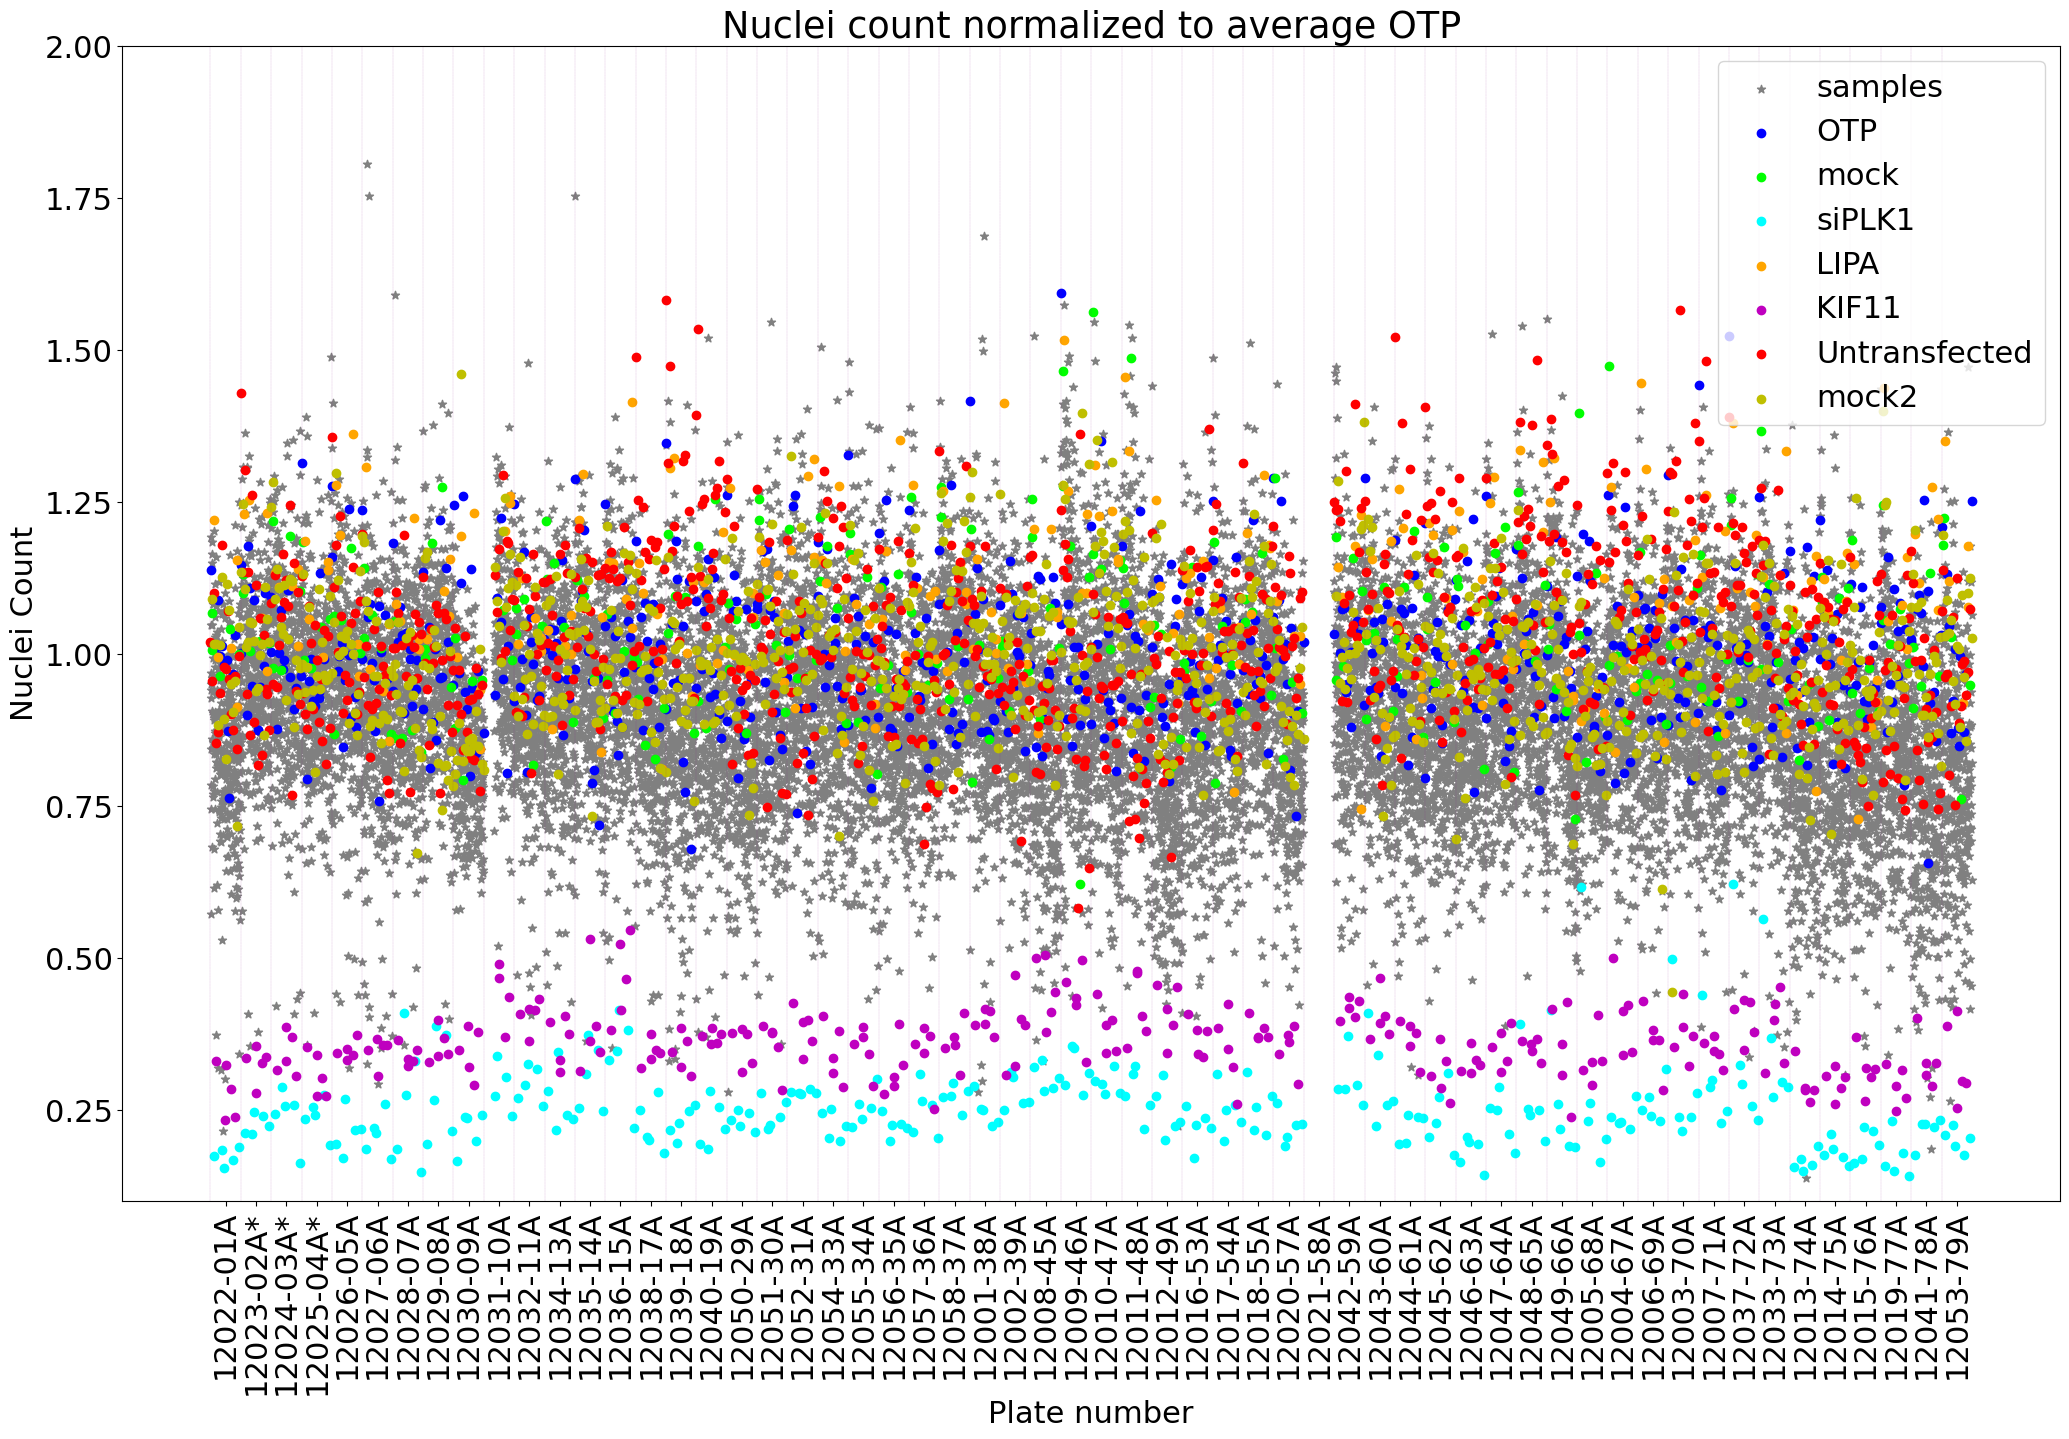

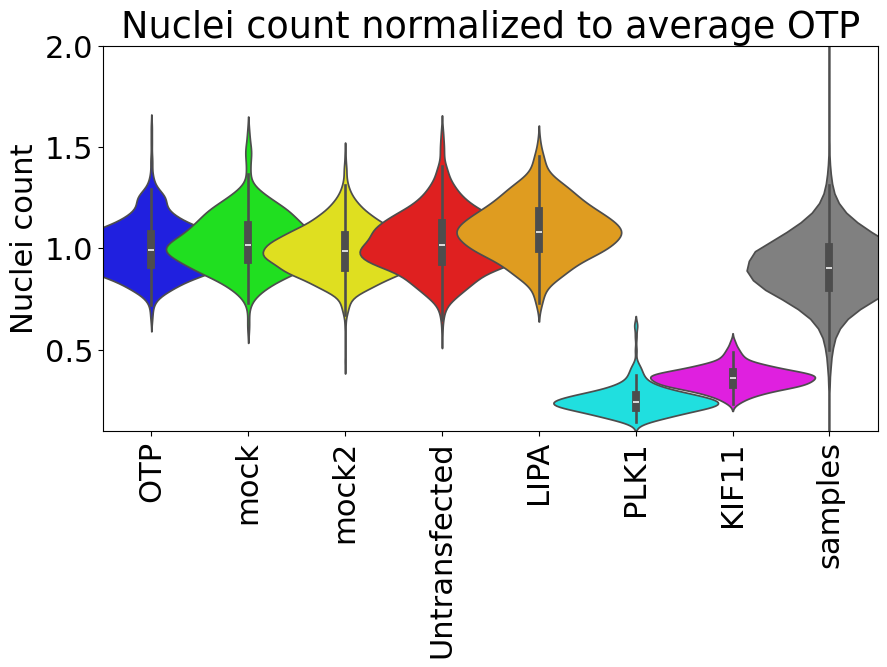

In [10]:
#COPY
# Reads saved json files

#import json so you dont have to run above cell if no new files needs saving
import json
import numpy as np
import os

#make all jsonfiles into keys


#create empty list
l = []
mock_well = []
OTP_well  = []
KIF11_well =[]
LIPA_well = []
PLK1_well = []
mock2_well= []
untr_well = []
label_X = []
all_plate_well = []

#loop through all keys (jsonfiles), load, add key to the empty list l
for k in Barcode_A:
    f4 = barcode_plate.loc[barcode_plate['Barcode']==k,'4fields'].values[0]
    lb = k.split('-SA-')[1]+str((bool(f4))).replace('True','*').replace('False','')
    label_X.append(lb)
    plate_data = np.zeros([16,24])
    pl   = barcode_plate.loc[barcode_plate['Barcode']==k, 'Plate'].values[0]
   
    if len(pl) != 0:
        with open('csv_files/A/'+pl.replace('MFGTMPcx7_','')+'_count.json','r') as f:
        
        ###Normalizing to avg of OTP wells
            json_str   = json.load(f)
            json_dict  = json.loads(json_str)
            plate_data = np.array(json_dict['data'])
             ##OTP


            ## This whole part is for adding 4 more field##
            P_ID  = pl
           
            ff =barcode_plate.loc[barcode_plate['Plate']==P_ID, '4fields'].values[0]
            fourfields = 'csv_files/A/4field/'+ff.replace('MFGTMPcx7_','')+'_count.json'
            if os.path.exists(fourfields):
                with open(fourfields,'r') as f:
                    second_json_4fields = json.load(f)
                    second_json_dict_4fields = json.loads(second_json_4fields)


                    second_plate_data = np.array(second_json_dict_4fields['data'])
                    plate_data = (plate_data+second_plate_data)*0.8


    OTP_per_plate =plate_data *np.array(OTP)
    otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
    plate_data = plate_data/otp_avg


    ##samples
    l.append(plate_data*np.array(samples))

    ##controls
    mock_well.append(plate_data*np.array(mock))
    OTP_well.append(plate_data*np.array(OTP))
    KIF11_well.append(plate_data*np.array(KIF11))
    LIPA_well.append(plate_data*np.array(LIPA))
    PLK1_well.append(plate_data*np.array(PLK1))
    mock2_well.append(plate_data*np.array(mock2))
    untr_well.append(plate_data*np.array(untr))

    all_plate_well.append(plate_data)
      
            

          
    

#label_X= plateNr
print(len(label_X))
       
#make list into array
array_all_plates = np.array(l)
mock_plates = np.array(mock_well)
OTP_plates = np.array(OTP_well)
KIF11_plates = np.array(KIF11_well)
LIPA_plates = np.array(LIPA_well)
PLK1_plates = np.array(PLK1_well)
untr_plates = np.array(untr_well)
mock2_plates = np.array(mock2_well)


all_plates = np.array(all_plate_well)


num_of_plates = len(Barcode_A)


all_for_plot = np.zeros([1,num_of_plates*384])
mock_for_plot = np.zeros([1,num_of_plates*384])
OTP_for_plot = np.zeros([1,num_of_plates*384])
KIF11_for_plot = np.zeros([1,num_of_plates*384])
LIPA_for_plot = np.zeros([1,num_of_plates*384])
PLK1_for_plot = np.zeros([1,num_of_plates*384])
untr_for_plot = np.zeros([1,num_of_plates*384])
mock2_for_plot = np.zeros([1,num_of_plates*384])

all_plate_for_plot = np.zeros([1,num_of_plates*384])

for plate_n in range(num_of_plates):
    wells = np.reshape(array_all_plates[plate_n,:,:],(1,384))
    all_for_plot[0,plate_n*384:(plate_n+1)*(384)]= wells

    mock_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock_plates[plate_n,:,:],(1,384))
    OTP_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(OTP_plates[plate_n,:,:],(1,384))
    KIF11_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(KIF11_plates[plate_n,:,:],(1,384))
    LIPA_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(LIPA_plates[plate_n,:,:],(1,384))
    PLK1_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(PLK1_plates[plate_n,:,:],(1,384))
    untr_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(untr_plates[plate_n,:,:],(1,384))
    mock2_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock2_plates[plate_n,:,:],(1,384))
    
    all_plate_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(all_plates[plate_n,:,:],(1,384)) 
    

#fig = plt.figure(figsize=(15,20))
#ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes

fig, ax1 = plt.subplots(1,1,figsize=(25,15))



plt.scatter(np.arange(all_for_plot.shape[1]),all_for_plot[0],color='gray',marker='*')

plt.scatter(np.arange((OTP_for_plot.shape[1])),OTP_for_plot,color='blue')
plt.scatter(np.arange((mock_for_plot.shape[1])),mock_for_plot,color='lime')

plt.scatter(np.arange((PLK1_for_plot.shape[1])),PLK1_for_plot,color ='cyan')

plt.scatter(np.arange((LIPA_for_plot.shape[1])),LIPA_for_plot,color='orange')
plt.scatter(np.arange((KIF11_for_plot.shape[1])),KIF11_for_plot,color='m')

plt.scatter(np.arange((untr_for_plot.shape[1])),untr_for_plot,color='r')

plt.scatter(np.arange((mock2_for_plot.shape[1])),mock2_for_plot,color='y')


X      = np.arange(num_of_plates)*384

plt.vlines(x=X,ymin=0,ymax=40000,colors='purple', ls='--', lw=0.1)


ax1.set_xticks(X+192)

ax1.set_xticklabels(label_X, rotation=90)
plt.xlabel('Plate number')
plt.ylabel('Nuclei Count')
plt.rcParams.update({'font.size': 22})
plt.ylim([0.1,2])
plt.legend(['samples','OTP','mock','siPLK1','LIPA','KIF11','Untransfected','mock2'])
plt.title('Nuclei count normalized to average OTP')


fig, ax2 = plt.subplots(1,1,figsize=(10,5))

sns.violinplot([OTP_for_plot[OTP_for_plot>0],mock_for_plot[mock_for_plot>0],
                mock2_for_plot[mock2_for_plot>0],untr_for_plot[untr_for_plot>0],LIPA_for_plot[LIPA_for_plot>0],
                PLK1_for_plot[PLK1_for_plot>0],
                KIF11_for_plot[KIF11_for_plot>0],all_for_plot[all_for_plot>0]],
                palette=['blue','lime','yellow','red','orange','cyan','magenta','gray'],width=1.7)
label_X = ['OTP','mock','mock2','Untransfected','LIPA','PLK1','KIF11','samples']
ax2.set_xticklabels(label_X, rotation=90)

plt.ylim([0.1,2])

plt.ylabel('Nuclei count')
plt.title('Nuclei count normalized to average OTP')

np.save('A_normalized_count.npy',all_plate_for_plot,allow_pickle=True)


### Combine Nuclei count with four fields

In the following cells we first merge main plates with 4 field plates and then normalize them

In [129]:
plateNr = !ls csv_files/A/*.csv  | sed s/'.csv'/''/g 
plateNr

['csv_files/A/MFGTMPcx7_170521130001',
 'csv_files/A/MFGTMPcx7_170522080001',
 'csv_files/A/MFGTMPcx7_170523020001',
 'csv_files/A/MFGTMPcx7_170525010001',
 'csv_files/A/MFGTMPcx7_170525180001',
 'csv_files/A/MFGTMPcx7_170526140001',
 'csv_files/A/MFGTMPcx7_170527090001',
 'csv_files/A/MFGTMPcx7_170528040001',
 'csv_files/A/MFGTMPcx7_170529100001',
 'csv_files/A/MFGTMPcx7_170530110007',
 'csv_files/A/MFGTMPcx7_170531050001',
 'csv_files/A/MFGTMPcx7_170601210001',
 'csv_files/A/MFGTMPcx7_170602160001',
 'csv_files/A/MFGTMPcx7_170605150001',
 'csv_files/A/MFGTMPcx7_170607050001',
 'csv_files/A/MFGTMPcx7_170608110002',
 'csv_files/A/MFGTMPcx7_170609070001',
 'csv_files/A/MFGTMPcx7_170618050001',
 'csv_files/A/MFGTMPcx7_170619000001',
 'csv_files/A/MFGTMPcx7_170619190001',
 'csv_files/A/MFGTMPcx7_170621110001',
 'csv_files/A/MFGTMPcx7_170622060001',
 'csv_files/A/MFGTMPcx7_170623010001',
 'csv_files/A/MFGTMPcx7_170623200001',
 'csv_files/A/MFGTMPcx7_170624160001',
 'csv_files/A/MFGTMPcx7_1

#### The following cell is for creating _combined_area from combined .csv files of main plates with 4 fields
## DO not run it if you already have _combined_4fields.json files

In [130]:
#COPY for cell mean area
row_number = ['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P']
column_number = ['01','02','03','04','05','06','07','08','09','10','11','12','13','14','15','16','17','18','19','20','21','22','23','24']

#Create empty list
my_dict_cellSize = {}

# Access the value using the key
#my_dict_cellSize["MFGTMPcx7_170524210001"] 
for p in plateNr:
    temp_df_size = pd.read_csv(p+'.csv')
    P_ID   = p.split('/A/')[1]
    print(P_ID)
    
    fourfields =barcode_plate.loc[barcode_plate['Plate']==P_ID, '4fields'].values[0]
    
    
    if len(fourfields):
        print(fourfields,'yesss')
        second_df  = pd.read_csv('csv_files/A/4field/'+fourfields+'.csv')
        merged_df_size = pd.concat([temp_df_size, second_df], axis=0)
            
        temp_df_size = merged_df_size         
    
   
    new_df_cell_mean_area = pd.DataFrame(columns=column_number,index=row_number)
    for r in row_number:
        for c in column_number:
            well = r+c
            new_df_cell_mean_area.loc[r][c] = np.mean(temp_df_size[temp_df_size['Image_name'].str.contains('_'+well)]['Area']) #switched pattern to well
    my_dict_cellSize[p]=new_df_cell_mean_area


MFGTMPcx7_170521130001
MFGTMPcx7_170719220001 yesss
MFGTMPcx7_170522080001
MFGTMPcx7_170720030001 yesss
MFGTMPcx7_170523020001
MFGTMPcx7_170720090001 yesss
MFGTMPcx7_170525010001
MFGTMPcx7_170525180001
MFGTMPcx7_170526140001
MFGTMPcx7_170527090001
MFGTMPcx7_170528040001
MFGTMPcx7_170529100001
MFGTMPcx7_170530110007
MFGTMPcx7_170531050001
MFGTMPcx7_170601210001
MFGTMPcx7_170602160001
MFGTMPcx7_170605150001
MFGTMPcx7_170607050001
MFGTMPcx7_170608110002
MFGTMPcx7_170609070001
MFGTMPcx7_170618050001
MFGTMPcx7_170619000001
MFGTMPcx7_170619190001
MFGTMPcx7_170621110001
MFGTMPcx7_170622060001
MFGTMPcx7_170623010001
MFGTMPcx7_170623200001
MFGTMPcx7_170624160001
MFGTMPcx7_170625110001
MFGTMPcx7_170626060001
MFGTMPcx7_170701190001
MFGTMPcx7_170702140001
MFGTMPcx7_170703120001
MFGTMPcx7_170704080001
MFGTMPcx7_170706000001
MFGTMPcx7_170708180001
MFGTMPcx7_170709130001
MFGTMPcx7_170710080001
MFGTMPcx7_170711230001
MFGTMPcx7_170714010002
MFGTMPcx7_170714210001
MFGTMPcx7_170715160001
MFGTMPcx7_170716

In [131]:
# Saves dictionaries in json files, remove names of plates you already have jsons for in cell above before running
import json
for k in my_dict_cellSize.keys():
    json.dump(my_dict_cellSize[k].to_json(orient='split'), open(k.replace('MFGTMPcx7_','')+'_area_combined_4fields.json', 'w'))

### Normalize and merge 4fields for those plates that has 4 more fields for object area

In [11]:
Barcode_A    = [ba for ba in barcode_plate['Barcode'] if ba.endswith('A')]
Barcode_A  


['20170516-SA-12022-01A',
 '20170516-SA-12023-02A',
 '20170516-SA-12024-03A',
 '20170516-SA-12025-04A',
 '20170522-SA-12026-05A',
 '20170522-SA-12027-06A',
 '20170522-SA-12028-07A',
 '20170522-SA-12029-08A',
 '20170523-SA-12030-09A',
 '20170523-SA-12031-10A',
 '20170523-SA-12032-11A',
 '20170529-SA-12034-13A',
 '20170529-SA-12035-14A',
 '20170529-SA-12036-15A',
 '20170530-SA-12038-17A',
 '20170530-SA-12039-18A',
 '20170530-SA-12040-19A',
 '20170613-SA-12050-29A',
 '20170613-SA-12051-30A',
 '20170613-SA-12052-31A',
 '20170614-SA-12054-33A',
 '20170614-SA-12055-34A',
 '20170614-SA-12056-35A',
 '20170614-SA-12057-36A',
 '20170619-SA-12058-37A',
 '20170619-SA-12001-38A',
 '20170619-SA-12002-39A',
 '20170626-SA-12008-45A',
 '20170626-SA-12009-46A',
 '20170626-SA-12010-47A',
 '20170626-SA-12011-48A',
 '20170627-SA-12012-49A',
 '20170703-SA-12016-53A',
 '20170703-SA-12017-54A',
 '20170703-SA-12018-55A',
 '20170704-SA-12020-57A',
 '20170704-SA-12021-58A',
 '20170704-SA-12042-59A',
 '20170704-S

C:\Users\salma\AppData\Local\Temp\ipykernel_17412\1186362760.py:42: RuntimeWarning: Mean of empty slice.
  otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
c:\Users\salma\.conda\envs\SalmaEnv\envs\coderefinery\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\salma\AppData\Local\Temp\ipykernel_17412\1186362760.py:159: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(label_X, rotation=90)


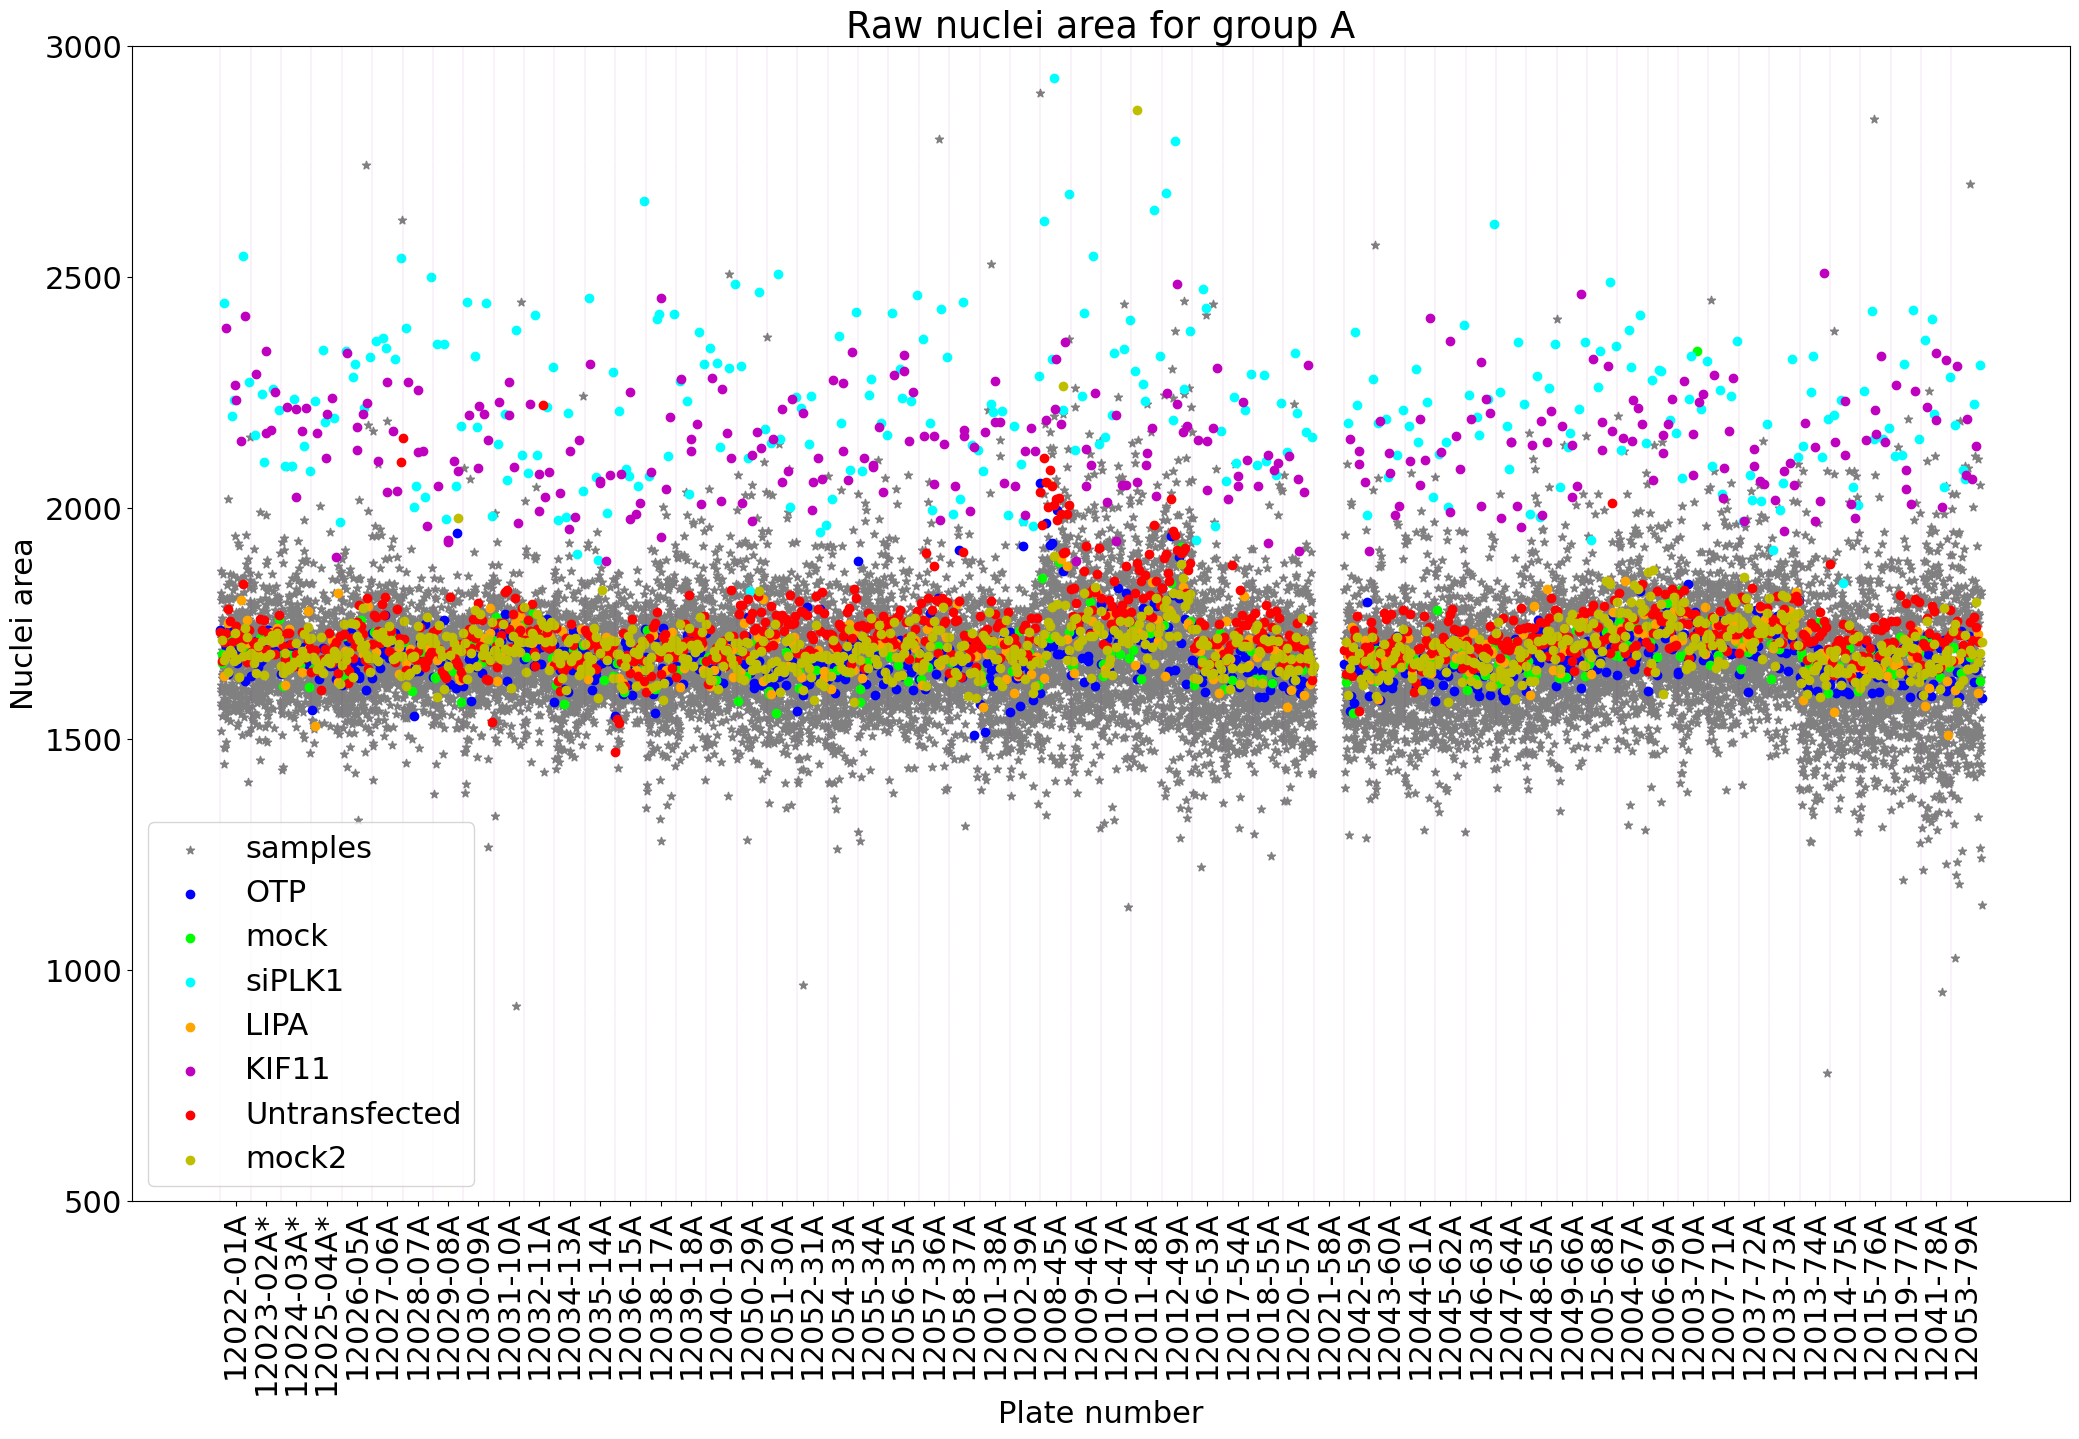

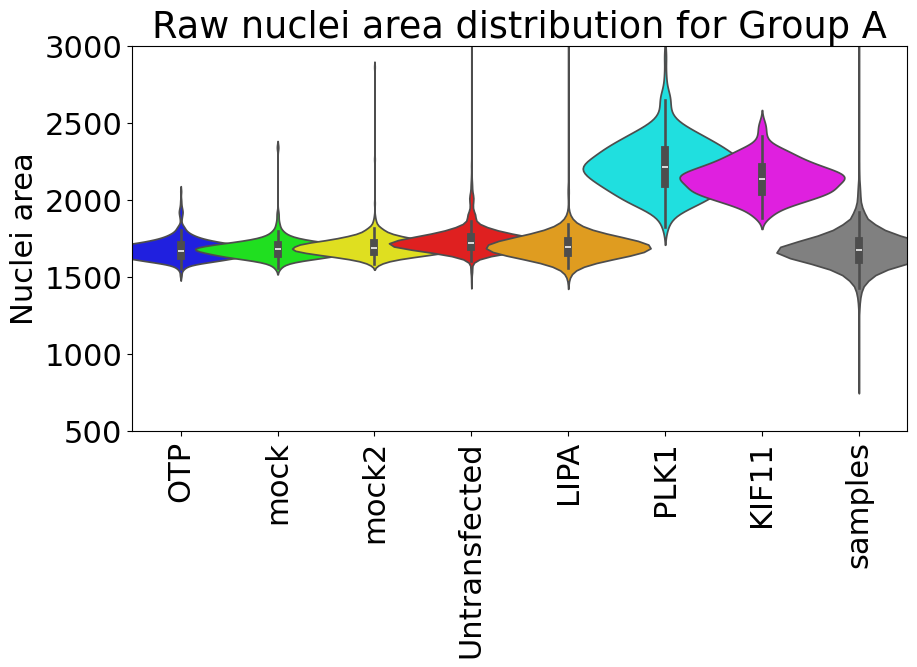

In [13]:
# Reads saved json files

#import json so you dont have to run above cell if no new files needs saving
import json
import numpy as np

#make all jsonfiles into keys


#create empty list
l = []
mock_well = []
OTP_well  = []
KIF11_well =[]
LIPA_well = []
PLK1_well = []
mock2_well= []
untr_well = []
label_X = []
all_plate_well = []

#loop through all keys (jsonfiles), load, add key to the empty list l
for k in Barcode_A:
            
    f4 = barcode_plate.loc[barcode_plate['Barcode']==k,'4fields'].values[0]
    lb = k.split('-SA-')[1]+str((bool(f4))).replace('True','*').replace('False','')
    label_X.append(lb)
    
    plate_data = np.zeros([16,24])
    pl   = barcode_plate.loc[barcode_plate['Barcode']==k, 'Plate'].values[0]
   
    if len(pl) != 0:
        with open('csv_files/A/'+pl.replace('MFGTMPcx7_','')+'_area_combined_4fields.json','r') as f:
        
            json_str = json.load(f)
            json_dict = json.loads(json_str)
            plate_data = np.array(json_dict['data'])
        
         ##OTP

    OTP_per_plate =plate_data *np.array(OTP)
    otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
    
    #plate_data = plate_data/otp_avg


    ##samples
    l.append(plate_data*np.array(samples))

    ##controls
    mock_well.append(plate_data*np.array(mock))
    OTP_well.append(plate_data*np.array(OTP))
    KIF11_well.append(plate_data*np.array(KIF11))
    LIPA_well.append(plate_data*np.array(LIPA))
    PLK1_well.append(plate_data*np.array(PLK1))
    mock2_well.append(plate_data*np.array(mock2))
    untr_well.append(plate_data*np.array(untr))

    all_plate_well.append(plate_data)

        
       
#make list into array
array_all_plates = np.array(l)
mock_plates = np.array(mock_well)
OTP_plates = np.array(OTP_well)
KIF11_plates = np.array(KIF11_well)
LIPA_plates = np.array(LIPA_well)
PLK1_plates = np.array(PLK1_well)
untr_plates = np.array(untr_well)
mock2_plates = np.array(mock2_well)


all_plates = np.array(all_plate_well)


num_of_plates = len(Barcode_A)


all_for_plot = np.zeros([1,num_of_plates*384])
mock_for_plot = np.zeros([1,num_of_plates*384])
OTP_for_plot = np.zeros([1,num_of_plates*384])
KIF11_for_plot = np.zeros([1,num_of_plates*384])
LIPA_for_plot = np.zeros([1,num_of_plates*384])
PLK1_for_plot = np.zeros([1,num_of_plates*384])
untr_for_plot = np.zeros([1,num_of_plates*384])
mock2_for_plot = np.zeros([1,num_of_plates*384])

all_plate_for_plot = np.zeros([1,num_of_plates*384])

for plate_n in range(num_of_plates):
    wells = np.reshape(array_all_plates[plate_n,:,:],(1,384))
    all_for_plot[0,plate_n*384:(plate_n+1)*(384)]= wells

    mock_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock_plates[plate_n,:,:],(1,384))
    OTP_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(OTP_plates[plate_n,:,:],(1,384))
    KIF11_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(KIF11_plates[plate_n,:,:],(1,384))
    LIPA_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(LIPA_plates[plate_n,:,:],(1,384))
    PLK1_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(PLK1_plates[plate_n,:,:],(1,384))
    untr_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(untr_plates[plate_n,:,:],(1,384))
    mock2_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock2_plates[plate_n,:,:],(1,384))
    
    all_plate_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(all_plates[plate_n,:,:],(1,384)) 
    

#fig = plt.figure(figsize=(15,20))
#ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes

fig, ax1 = plt.subplots(1,1,figsize=(25,15))



plt.scatter(np.arange(all_for_plot.shape[1]),all_for_plot[0],color='gray',marker='*')

plt.scatter(np.arange((OTP_for_plot.shape[1])),OTP_for_plot,color='blue')
plt.scatter(np.arange((mock_for_plot.shape[1])),mock_for_plot,color='lime')

plt.scatter(np.arange((PLK1_for_plot.shape[1])),PLK1_for_plot,color ='cyan')

plt.scatter(np.arange((LIPA_for_plot.shape[1])),LIPA_for_plot,color='orange')
plt.scatter(np.arange((KIF11_for_plot.shape[1])),KIF11_for_plot,color='m')

plt.scatter(np.arange((untr_for_plot.shape[1])),untr_for_plot,color='r')

plt.scatter(np.arange((mock2_for_plot.shape[1])),mock2_for_plot,color='y')

X      = np.arange(num_of_plates)*384

plt.vlines(x=X,ymin=0,ymax=40000,colors='purple', ls='--', lw=0.1)


#for k in keys_json:
    #label_X.append(k.replace('_count.json','').replace('CSV/A/',''))
#for k in Barcode:
#    label_X.append(k)
    

#label_X= plateNr
#print(len(label_X))
ax1.set_xticks(X+192)

ax1.set_xticklabels(label_X, rotation=90)
plt.xlabel('Plate number')
plt.ylabel('Nuclei area')
plt.rcParams.update({'font.size': 22})
plt.ylim([500,3000])
plt.legend(['samples','OTP','mock','siPLK1','LIPA','KIF11','Untransfected','mock2'])
plt.title('Raw nuclei area for group A')


fig, ax2 = plt.subplots(1,1,figsize=(10,5))

sns.violinplot([OTP_for_plot[OTP_for_plot>0],mock_for_plot[mock_for_plot>0],
                mock2_for_plot[mock2_for_plot>0],untr_for_plot[untr_for_plot>0],LIPA_for_plot[LIPA_for_plot>0],
                PLK1_for_plot[PLK1_for_plot>0],
                KIF11_for_plot[KIF11_for_plot>0],all_for_plot[all_for_plot>0]],
                palette=['blue','lime','yellow','red','orange','cyan','magenta','gray'],width=1.7)
label_X = ['OTP','mock','mock2','Untransfected','LIPA','PLK1','KIF11','samples']
ax2.set_xticklabels(label_X, rotation=90)
plt.ylabel('Nuclei area')
plt.title('Raw nuclei area distribution for Group A')
plt.ylim([500,3000])


np.save('A_area.npy',all_plate_for_plot,allow_pickle=True)

C:\Users\salma\AppData\Local\Temp\ipykernel_17412\1907649906.py:48: RuntimeWarning: Mean of empty slice.
  otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
c:\Users\salma\.conda\envs\SalmaEnv\envs\coderefinery\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


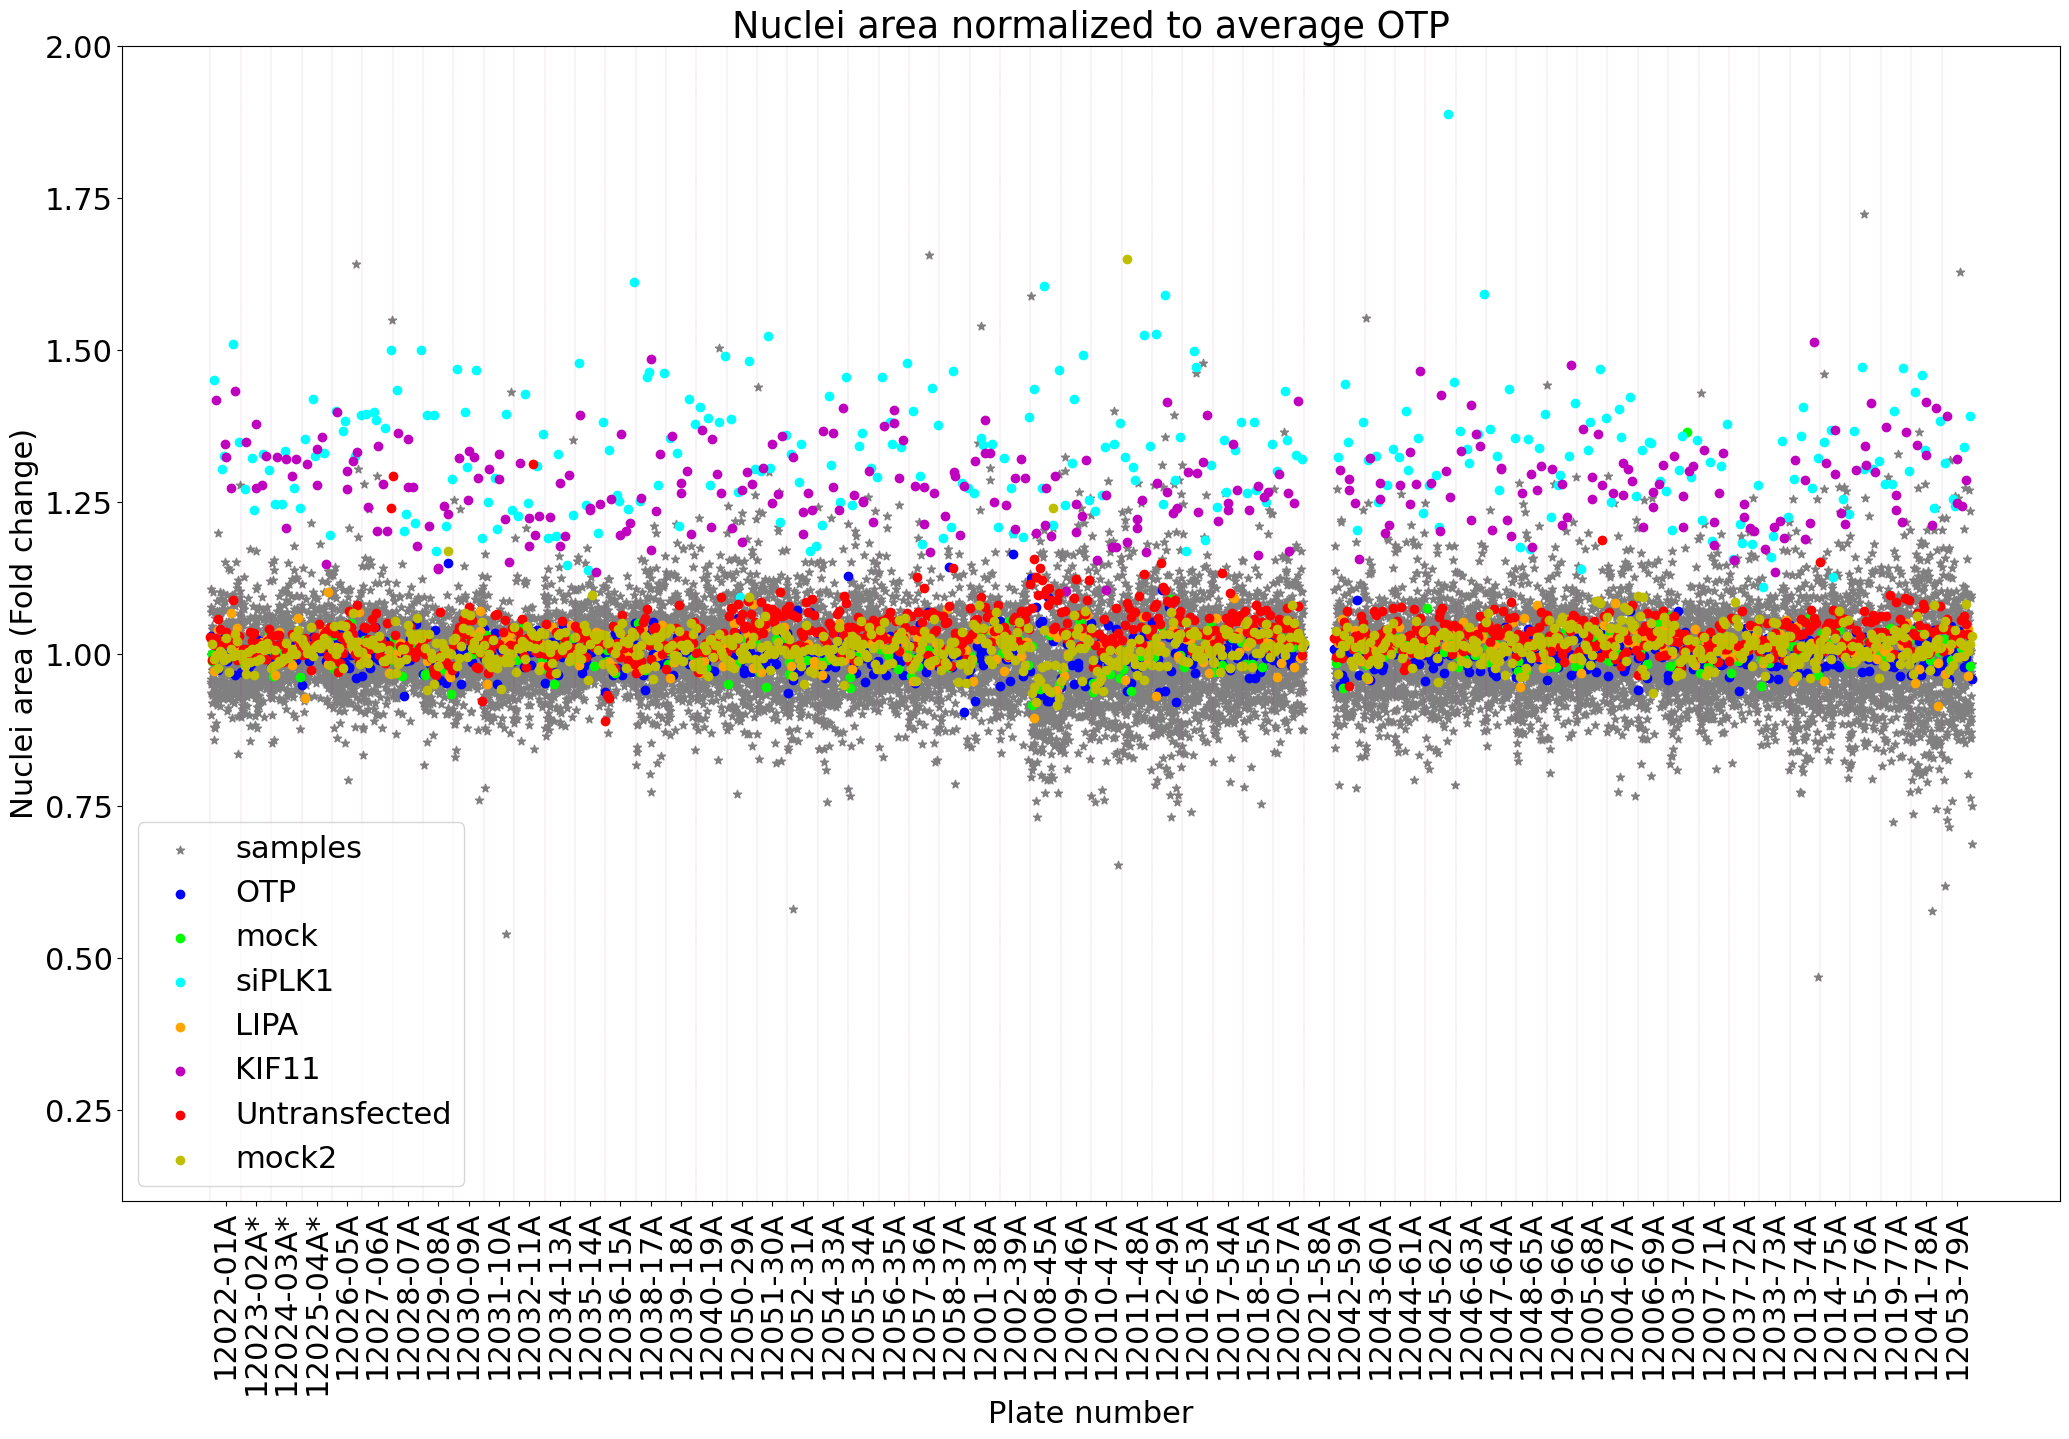

In [17]:

#COPY
# Reads saved json files

#import json so you dont have to run above cell if no new files needs saving
import json
import numpy as np

#make all jsonfiles into keys



#create empty list
l = []
mock_well = []
OTP_well  = []
KIF11_well =[]
LIPA_well = []
PLK1_well = []
mock2_well= []
untr_well = []

all_plate_well = []
label_X = []
#loop through all keys (jsonfiles), load, add key to the empty list l
for k in Barcode_A:
            
    f4 = barcode_plate.loc[barcode_plate['Barcode']==k,'4fields'].values[0]
    lb = k.split('-SA-')[1]+str((bool(f4))).replace('True','*').replace('False','')
    label_X.append(lb)
    
    plate_data = np.zeros([16,24])
    pl   = barcode_plate.loc[barcode_plate['Barcode']==k, 'Plate'].values[0]
   
    if len(pl) != 0:
        with open('csv_files/A/'+pl.replace('MFGTMPcx7_','')+'_area_combined_4fields.json','r') as f:
        
       
        
            json_str = json.load(f)
            json_dict = json.loads(json_str)
            plate_data = np.array(json_dict['data'])
        
        
        
         ##OTP

    OTP_per_plate =plate_data *np.array(OTP)
    otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
    #print(otp_avg)
    plate_data = plate_data/otp_avg


    ##samples
    l.append(plate_data*np.array(samples))

    ##controls
    mock_well.append(plate_data*np.array(mock))
    OTP_well.append(plate_data*np.array(OTP))
    KIF11_well.append(plate_data*np.array(KIF11))
    LIPA_well.append(plate_data*np.array(LIPA))
    PLK1_well.append(plate_data*np.array(PLK1))
    mock2_well.append(plate_data*np.array(mock2))
    untr_well.append(plate_data*np.array(untr))

    all_plate_well.append(plate_data)


       
#make list into array
array_all_plates = np.array(l)
mock_plates = np.array(mock_well)
OTP_plates = np.array(OTP_well)
KIF11_plates = np.array(KIF11_well)
LIPA_plates = np.array(LIPA_well)
PLK1_plates = np.array(PLK1_well)
untr_plates = np.array(untr_well)
mock2_plates = np.array(mock2_well)


all_plates = np.array(all_plate_well)


num_of_plates = len(Barcode_A)


all_for_plot = np.zeros([1,num_of_plates*384])
mock_for_plot = np.zeros([1,num_of_plates*384])
OTP_for_plot = np.zeros([1,num_of_plates*384])
KIF11_for_plot = np.zeros([1,num_of_plates*384])
LIPA_for_plot = np.zeros([1,num_of_plates*384])
PLK1_for_plot = np.zeros([1,num_of_plates*384])
untr_for_plot = np.zeros([1,num_of_plates*384])
mock2_for_plot = np.zeros([1,num_of_plates*384])

all_plate_for_plot = np.zeros([1,num_of_plates*384])

for plate_n in range(num_of_plates):
    wells = np.reshape(array_all_plates[plate_n,:,:],(1,384))
    all_for_plot[0,plate_n*384:(plate_n+1)*(384)]= wells

    mock_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock_plates[plate_n,:,:],(1,384))
    OTP_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(OTP_plates[plate_n,:,:],(1,384))
    KIF11_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(KIF11_plates[plate_n,:,:],(1,384))
    LIPA_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(LIPA_plates[plate_n,:,:],(1,384))
    PLK1_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(PLK1_plates[plate_n,:,:],(1,384))
    untr_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(untr_plates[plate_n,:,:],(1,384))
    mock2_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock2_plates[plate_n,:,:],(1,384))
    
    all_plate_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(all_plates[plate_n,:,:],(1,384)) 
    

#fig = plt.figure(figsize=(15,20))
#ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes

fig, ax1 = plt.subplots(1,1,figsize=(25,15))



plt.scatter(np.arange(all_for_plot.shape[1]),all_for_plot[0],color='gray',marker='*')

plt.scatter(np.arange((OTP_for_plot.shape[1])),OTP_for_plot,color='blue')
plt.scatter(np.arange((mock_for_plot.shape[1])),mock_for_plot,color='lime')

plt.scatter(np.arange((PLK1_for_plot.shape[1])),PLK1_for_plot,color ='cyan')

plt.scatter(np.arange((LIPA_for_plot.shape[1])),LIPA_for_plot,color='orange')
plt.scatter(np.arange((KIF11_for_plot.shape[1])),KIF11_for_plot,color='m')

plt.scatter(np.arange((untr_for_plot.shape[1])),untr_for_plot,color='r')

plt.scatter(np.arange((mock2_for_plot.shape[1])),mock2_for_plot,color='y')



X      = np.arange(num_of_plates)*384

plt.vlines(x=X,ymin=0,ymax=40000,colors='purple', ls='--', lw=0.1)


#for k in keys_json:
#    label_X.append(k.replace('_count.json','').replace('CSV/A/',''))
   

#label_X= plateNr

ax1.set_xticks(X+192)

ax1.set_xticklabels(label_X, rotation=90)
plt.xlabel('Plate number')
plt.ylabel('Nuclei area (Fold change)')
plt.rcParams.update({'font.size': 22})
plt.ylim([0.1,2])
plt.legend(['samples','OTP','mock','siPLK1','LIPA','KIF11','Untransfected','mock2'])
plt.title('Nuclei area normalized to average OTP')


np.save('A_normalized_area.npy',all_plate_for_plot, allow_pickle=True)